# 06. LSOA distances, quarterly spatial diagnostics, and neighbouring crime

This experiment uses the same transaction-level spatial sample for the own-crime M7-style benchmark, SLX regressions, and quarterly Moran diagnostics. All price regressions include LSOA and year-quarter fixed effects. Moran's I is calculated each sale quarter after transaction residuals are averaged within LSOA-quarter. Raw mean log price and mean log(1 + prior-12-month MPS crime) are also described at LSOA-quarter level. Representative coordinates average distinct observed sale-location points, **not official polygon centroids**.

The 4-, 8-, and 12-neighbour graphs use inverse-distance, row-standardised weights. Spatial diagnostics are descriptive; neither Moran's I nor the SLX coefficient identifies a causal crime spillover.

In [1]:
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    ROOT=Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT=Path('/content/drive/MyDrive/HE3027 Project')
DATA_DIR=ROOT/'data'
MERGED=DATA_DIR/'crime_housing_merged.csv.gz'
if not MERGED.is_file():raise FileNotFoundError('Run the data-audit notebook first.')

OUT=DATA_DIR/'06_crime_spatial_outputs';OUT.mkdir(exist_ok=True)
SEED=302706
NEIGHBOUR_COUNTS=[4,8,12]
PERMUTATIONS=199
YEARS=[2012,2013,2014,2015]


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


In [3]:
df=pd.read_csv(MERGED,low_memory=False)
assert df.transaction_id.is_unique


In [4]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
data['Nearest_Park_dist_km'] = data['Nearest_Park_dist'] / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
    LOCATION += ['dist_to_cbd','Nearest_Park_dist_km']
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})


In [5]:
MAIN=['mps_all','mps_violence','mps_property']
CRIME_NAMES=dict(zip(MAIN,['All crime','Violence','Property crime']))
CONTROLS=PROPERTY+LOCATION+[c for c in ECONOMIC if c!='jobdensity']
for c in MAIN:data['log1p_'+c]=np.log1p(data[c+'_prior12'])
required=['lnprice','lsoacode','msoa11','oslaua','yearquarter','year','lat','lon']+CONTROLS+['log1p_'+c for c in MAIN]
valid=data[required].replace('',np.nan).notna().all(axis=1)
valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
valid &= data.analysis_geography_ok & data.mps_exposures_available & data.mps_geography_ok
eligible=data.loc[valid].copy()


## 1. Representative LSOA locations and distances

Distances use great-circle kilometres on a sphere (Earth radius 6,371 km), not degrees. A three-dimensional unit-sphere KD tree finds nearest neighbours without creating a dense 4,000-by-4,000 matrix. Self-links are excluded. Each graph has inverse-distance weights, row-standardised to one; k-nearest links are directed and need not be reciprocal. K=4, 8 and 12 are reported, not selected for coefficient signs. Border neighbours outside the London study coverage are absent.

The left map displays all study LSOA representative points and links for a fixed sample of 50 LSOAs, so the London-wide network is legible. The right map uses [ONS 2011 generalised clipped LSOA boundaries](https://services1.arcgis.com/ESMARspQHYMw9BZ9/arcgis/rest/services/LSOA_Dec_2011_Boundaries_Generalised_Clipped_BGC_EW_V3/FeatureServer/0) to outline one orange LSOA and its eight blue nearest LSOAs. Numbers rank neighbours by point-to-point distance; the links are based on representative sale-location points, not shared borders. The cached boundary GeoJSON is in `project_data/boundaries/`. A lookup function below computes the distance for any two saved LSOAs. The neighbour CSV gives the closest twelve for each area, including names/codes, distances and weights. Nearest points can lie across rivers or other barriers.


In [6]:
from scipy.spatial import cKDTree
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from matplotlib.collections import LineCollection
locations=eligible[['lsoacode','lat','lon']].drop_duplicates().groupby('lsoacode')[['lat','lon']].mean()
assert locations.lat.between(50,53).all() and locations.lon.between(-1,1).all()
agg={'lnprice':'mean','price':'median',**{c:'mean' for c in CONTROLS},**{'log1p_'+c:'mean' for c in MAIN}}
area=eligible.loc[eligible.year.isin(YEARS)].groupby(['lsoacode','year']).agg(agg).reset_index()
area['sales']=eligible.loc[eligible.year.isin(YEARS)].groupby(['lsoacode','year']).size().to_numpy()
balanced=area.groupby('lsoacode').year.nunique().eq(len(YEARS))
codes=np.array(sorted(balanced.index[balanced]))
locations=locations.loc[codes]
area=area.loc[area.lsoacode.isin(codes)].sort_values(['year','lsoacode']).reset_index(drop=True)
assert len(area)==len(codes)*len(YEARS)
locations.to_csv(OUT/'lsoa_representative_coordinates.csv')
lat=np.deg2rad(locations.lat.to_numpy());lon=np.deg2rad(locations.lon.to_numpy())
xyz=np.column_stack([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])
tree=cKDTree(xyz)
chord,indices=tree.query(xyz,k=max(NEIGHBOUR_COUNTS)+1)
# Coordinates can coincide; remove the actual own index rather than assuming first position.
neighbours=[];distances=[]
for i in range(len(codes)):
    keep=indices[i]!=i
    neighbours.append(indices[i][keep][:max(NEIGHBOUR_COUNTS)])
    distances.append(2*6371*np.arcsin(np.clip(chord[i][keep][:max(NEIGHBOUR_COUNTS)]/2,0,1)))
neighbours=np.array(neighbours);distances=np.array(distances)
weights={};edges=[]
for k in NEIGHBOUR_COUNTS:
    d=distances[:,:k];w=1/np.maximum(d,.001);w/=w.sum(axis=1,keepdims=True)
    W=sparse.csr_matrix((w.ravel(),(np.repeat(np.arange(len(codes)),k),neighbours[:,:k].ravel())),shape=(len(codes),len(codes)))
    assert np.allclose(W.sum(axis=1),1) and np.allclose(W.diagonal(),0)
    weights[k]=W;sparse.save_npz(OUT/f'weights_knn{k}.npz',W)
    edges.append(pd.DataFrame({'lsoacode':np.repeat(codes,k),'neighbour':codes[neighbours[:,:k].ravel()],'distance_km':d.ravel(),'weight':w.ravel(),'k':k}))
edges=pd.concat(edges,ignore_index=True);edges.to_csv(OUT/'lsoa_neighbour_distances.csv.gz',index=False,compression='gzip')
def lsoa_distance_km(first,second):
    a=locations.loc[first].to_numpy();b=locations.loc[second].to_numpy()
    a,b=np.deg2rad(a),np.deg2rad(b)
    h=np.sin((a[0]-b[0])/2)**2+np.cos(a[0])*np.cos(b[0])*np.sin((a[1]-b[1])/2)**2
    return float(2*6371*np.arcsin(np.sqrt(np.clip(h,0,1))))
print('Balanced spatial panel:',len(codes),'LSOAs;',len(area),'LSOA-years')
print('Example distance:',codes[0],codes[1],lsoa_distance_km(codes[0],codes[1]),'km')
table(edges.groupby('k').distance_km.describe(),'neighbour_distance_distribution')
table(pd.DataFrame([dict(k=k,weak_components=connected_components(weights[k],directed=True,connection='weak')[0]) for k in NEIGHBOUR_COUNTS]),'graph_connectivity')


Balanced spatial panel: 4435 LSOAs; 17740 LSOA-years
Example distance: E01000006 E01000007 0.8613012435959158 km


,count,mean,std,min,25%,50%,75%,max
k,,,,,,,,
4,17740.0,0.4784,0.1867,0.0189,0.3551,0.4471,0.5644,2.6245
8,35480.0,0.6182,0.2684,0.0189,0.4355,0.5748,0.7526,4.5232
12,53220.0,0.7375,0.3406,0.0189,0.5053,0.6885,0.9089,5.6252


,k,weak_components
0,4,3
1,8,1
2,12,1


Neighbour map: /home/rachmiel/he3027/data/06_crime_spatial_outputs/lsoa_neighbour_map.png


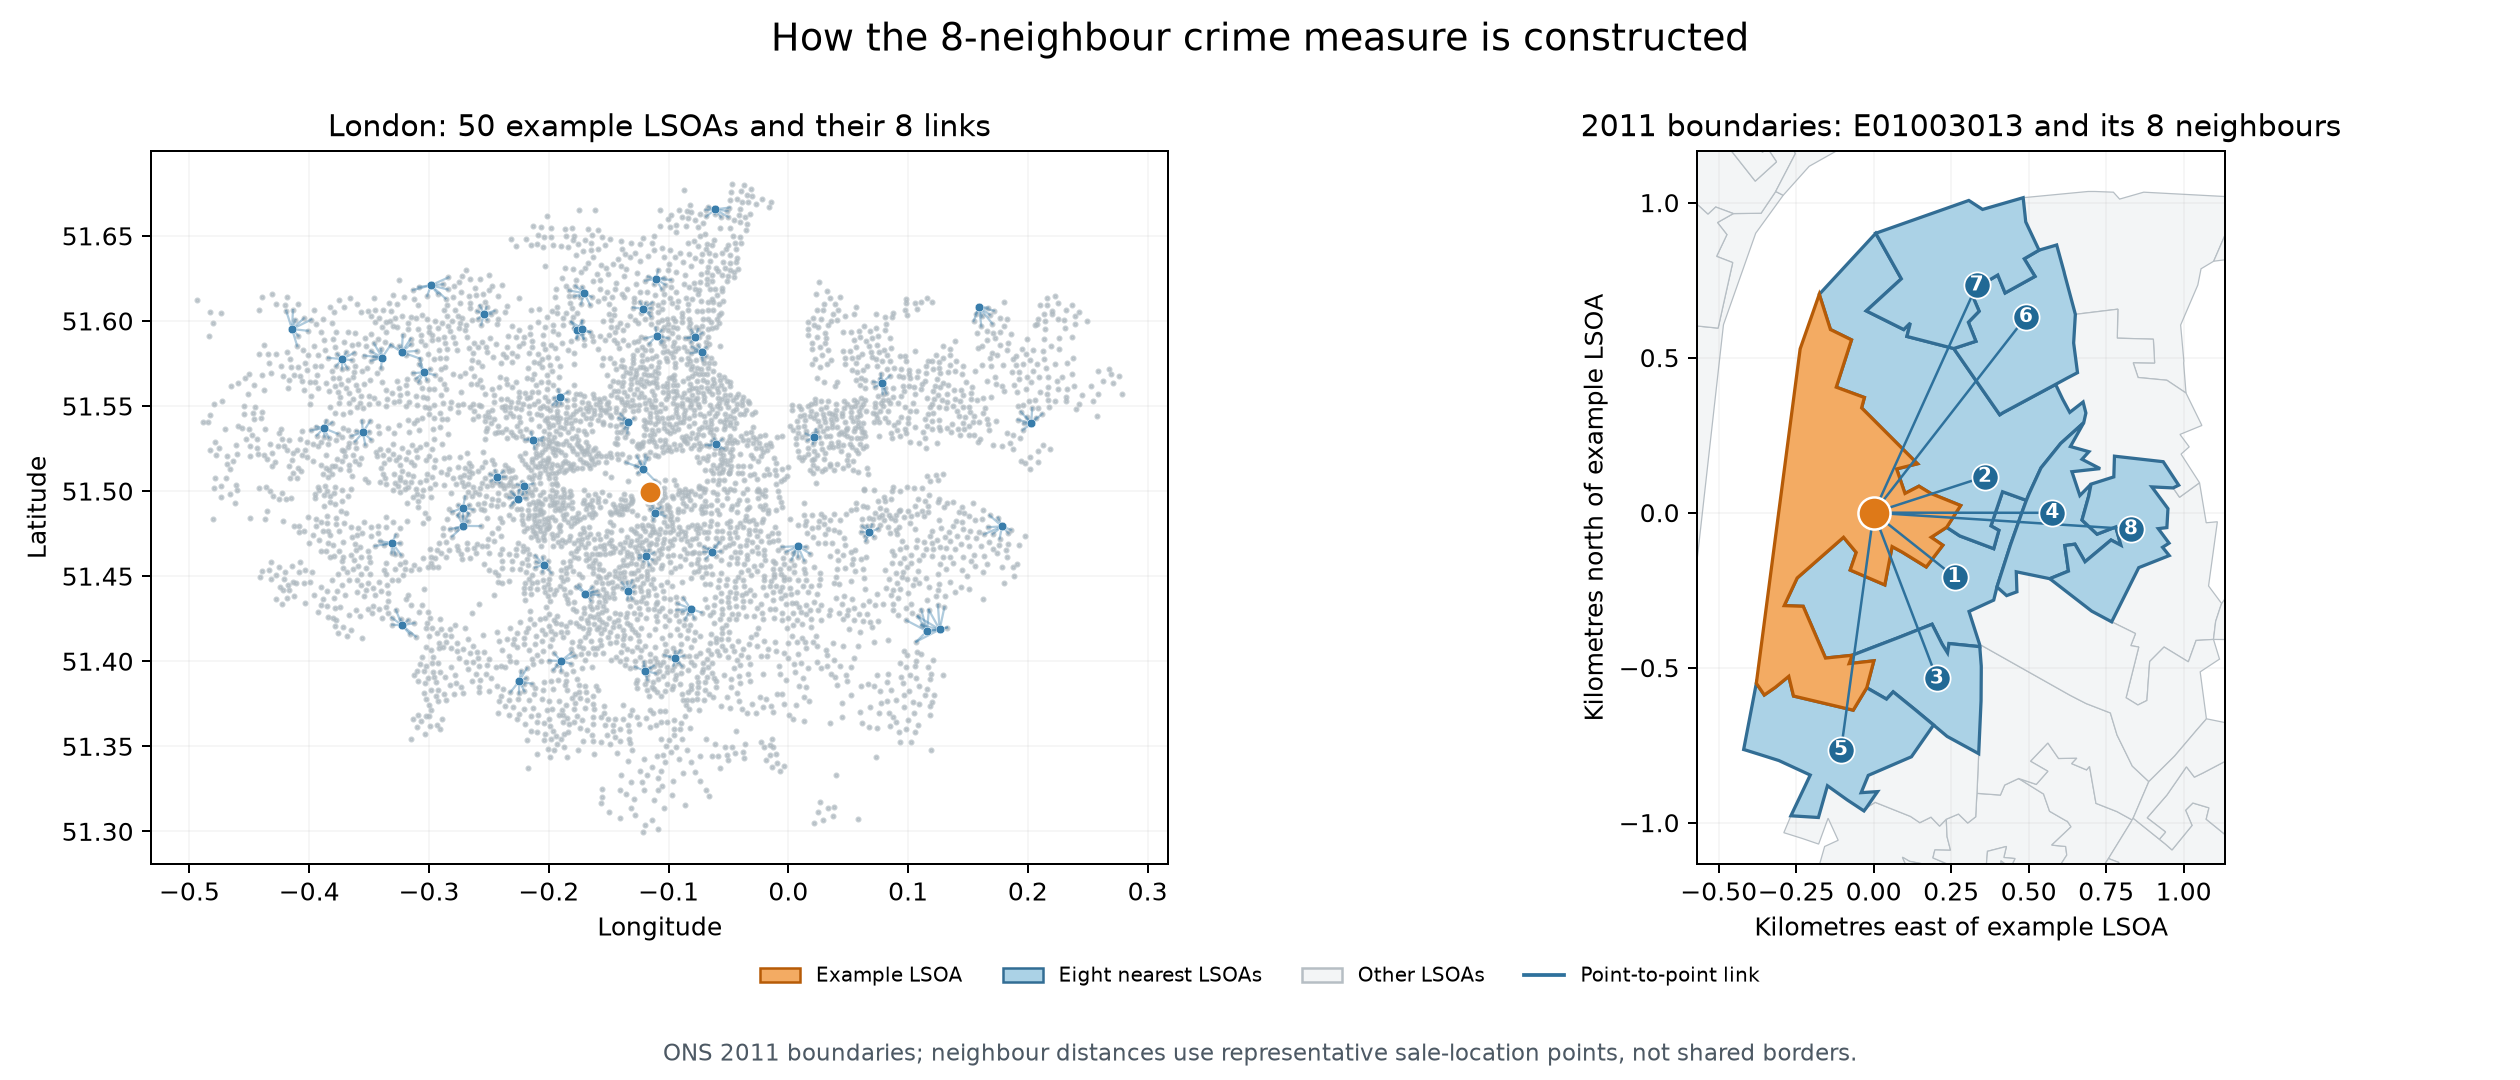

In [7]:
import sys
sys.path.insert(0, str(ROOT))
from utils.plot_lsoa_neighbours import make_plot
print('Neighbour map:', make_plot(ROOT))
display(__import__('IPython').display.Image(filename=str(OUT/'lsoa_neighbour_map.png')))


## 2. Transaction-level spatial regressions

The own-crime benchmark and all SLX models use identical sales, property/location/economic controls, LSOA and year-quarter fixed effects, and LSOA-clustered standard errors. The graph is built from LSOAs with sales in every study year so the same locations can be followed over time. Quarterly Moran diagnostics below use only LSOAs with sales in that quarter; coverage is reported.

In [8]:
from linearmodels.iv import AbsorbingLS
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    """Estimate OLS with high-dimensional fixed effects using linearmodels."""
    names = ([crime] if crime is not None else []) + controls
    x = data[names].astype(float).copy()
    y = data.lnprice.astype(float).copy()
    scale = x.std(axis=0).to_numpy().copy()
    scale[scale < 1e-14] = 1
    x_scaled = x / scale
    if fixed_effects:
        absorbed = pd.DataFrame(
            {c: pd.Categorical(data[c]) for c in fixed_effects}, index=data.index
        )
    else:
        absorbed = None
        y = y - y.mean()
        x_scaled = x_scaled - x_scaled.mean(axis=0)
    fit = AbsorbingLS(
        y, x_scaled, absorb=absorbed, drop_absorbed=True
    ).fit(cov_type='clustered', clusters=data[cluster], debiased=True)
    group = pd.factorize(data[cluster], sort=False)[0]
    G = int(group.max() + 1)
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    identified = list(fit.params.index)
    if crime is not None and crime not in identified:
        raise ValueError('Crime has no identifying variation in this specification')
    estimates = fit.params.to_numpy() / scale[[names.index(c) for c in identified]]
    se = fit.std_errors.to_numpy() / scale[[names.index(c) for c in identified]]
    critical = stats.t.ppf(0.975, G - 1)
    j = identified.index(crime) if crime is not None else 0
    result = {
        'N': len(data), 'clusters': G,
        'beta': estimates[j] if crime is not None else np.nan,
        'se': se[j] if crime is not None else np.nan,
        'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1) if crime is not None else np.nan,
        'ci_low': estimates[j] - critical * se[j] if crime is not None else np.nan,
        'ci_high': estimates[j] + critical * se[j] if crime is not None else np.nan,
        'r2': fit.rsquared, 'r2_type': 'within' if fixed_effects else 'ordinary',
        'crime_residual_sd': x_scaled.iloc[:, names.index(crime)].std() * scale[names.index(crime)] if crime is not None else np.nan,
        'iterations': 0,
        'absorbed_or_collinear': '; '.join(c for c in names if c not in identified),
        'fixed_effects': '; '.join(fixed_effects),
    }
    coefficients = pd.DataFrame({
        'variable': identified, 'beta': estimates, 'se': se,
    })
    return (result, coefficients, fit.resids.to_numpy().reshape(-1))



## 3. Transaction-level own and neighbouring crime: SLX

For sale $i$ in LSOA $l$ and sale month $t$, estimate $\ln P_{i,t}=\beta C_{l,t}+\theta(WC)_{l,t}+\gamma'X_{i,t}+\mu_l+\lambda_{q(t)}+u_{i,t}$. Crime is log(1 + MPS offences in the 12 completed months before sale). Neighbour crime is the distance-weighted mean of the same rolling exposure for nearby LSOAs in the same sale month. The weights are fixed by representative LSOA coordinates. We calculate neighbour exposures from the complete monthly MPS panel, including months without a sale; an unavailable neighbour-month excludes that sale from the common SLX sample.

The own-crime benchmark and all SLX variants use identical transactions, property/location/economic controls, LSOA and year-quarter effects, and LSOA-clustered SEs. The sample is restricted to LSOAs in the balanced Moran graph and sales with all 12-neighbour exposures. The neighbour term is associational and does not remove shared spatial shocks or crime endogeneity. Clustering within LSOA does not account for cross-LSOA residual dependence.


In [9]:
# Rebuild the exact rolling exposure for every neighbouring LSOA-month, including
# months without a transaction. Match by the sale's own month, never by calendar year.
monthly=pd.read_csv(DATA_DIR/'mps_monthly_panel.csv.gz')
monthly['sale_month']=pd.PeriodIndex(monthly.pop('month'),freq='M')
monthly=monthly.set_index(['lsoacode','sale_month']).sort_index()
grid=pd.MultiIndex.from_product([monthly.index.get_level_values('lsoacode').unique(),pd.period_range('2010-04','2015-12',freq='M')],names=['lsoacode','sale_month'])
monthly=monthly.reindex(grid)
for category in MAIN:
    monthly['log1p_'+category]=np.log1p(monthly.groupby(level='lsoacode')[category].transform(lambda v:v.shift(1).rolling(12,min_periods=12).sum()))
rolling=monthly[['log1p_'+category for category in MAIN]]
slx=eligible.loc[eligible.lsoacode.isin(codes)].copy()
slx['sale_month']=pd.PeriodIndex(slx.sale_month,freq='M')
own_check=slx[['lsoacode','sale_month']].merge(rolling.reset_index(),on=['lsoacode','sale_month'],how='left',validate='many_to_one')
for category in MAIN:
    if not np.allclose(slx['log1p_'+category].to_numpy(),own_check['log1p_'+category].to_numpy(),equal_nan=True):
        raise ValueError('Monthly panel disagrees with the merged own-area prior12 exposure')
lookup=rolling.reset_index()
for k in NEIGHBOUR_COUNTS:
    weight=weights[k].toarray()[np.arange(len(codes))[:,None],neighbours[:,:k]]
    for category in MAIN:
        wide=lookup.pivot(index='sale_month',columns='lsoacode',values='log1p_'+category).reindex(columns=codes)
        values=wide.to_numpy()[:,neighbours[:,:k]]
        complete=np.isfinite(values).all(axis=2)
        lag=np.einsum('tlk,lk->tl',np.where(np.isfinite(values),values,0),weight)
        lag[~complete]=np.nan
        by_month=pd.DataFrame(lag,index=wide.index,columns=codes).stack().rename('W'+str(k)+'_'+category)
        by_month.index.names=['sale_month','lsoacode']
        slx=slx.join(by_month,on=['sale_month','lsoacode'])
needed=['W'+str(k)+'_'+category for k in NEIGHBOUR_COUNTS for category in MAIN]
slx=slx.dropna(subset=needed).copy()
if slx.empty:raise ValueError('No sales have complete neighbouring prior12 exposures')
print('Common transaction SLX sample:',len(slx),'sales;',slx.lsoacode.nunique(),'LSOAs')
table(slx.groupby('year').size().to_frame('sales'),'slx_sample_by_year')
settings=[('Own crime only',8,False),('Crime + 8 neighbours',8,True),('Crime + 4 neighbours',4,True),('Crime + 12 neighbours',12,True)]
rows=[];all_coefficients=[];transaction_residuals={}
for label,k,with_neighbour in settings:
    for category in MAIN:
        extra=['W'+str(k)+'_'+category] if with_neighbour else []
        result,coef,residual=fit_absorbed(slx,'log1p_'+category,CONTROLS+extra,['lsoacode','yearquarter'])
        transaction_residuals[(('slx'+str(k)) if with_neighbour else 'own',category)]=residual
        rows.append(dict(specification=label,k=k,crime=category,**result))
        all_coefficients.append(coef.assign(specification=label,k=k,crime=category))
spatial_results=pd.DataFrame(rows).assign(data_source='MPS',exposure='prior12',estimator='Spatial')
spatial_coefficients=pd.concat(all_coefficients,ignore_index=True)
assert len(spatial_results)==len(settings)*len(MAIN) and spatial_results.N.nunique()==1
table(spatial_results,'spatial_regressions')
spatial_coefficients.to_csv(OUT/'all_spatial_coefficients.csv',index=False)
slx[['transaction_id','lsoacode','sale_month']+needed].to_csv(OUT/'transaction_neighbour_crime.csv.gz',index=False,compression='gzip')


Common transaction SLX sample: 328703 sales; 4435 LSOAs


,sales
year,
2012,82450
2013,98576
2014,103890
2015,43787


,specification,k,crime,N,clusters,beta,...,iterations,absorbed_or_collinear,fixed_effects,data_source,exposure,estimator
0,Own crime only,8,mps_all,328703,4435,-1.8745e-05,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
1,Own crime only,8,mps_violence,328703,4435,-6.2089e-05,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
2,Own crime only,8,mps_property,328703,4435,1.4671e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
3,Crime + 8 neighbours,8,mps_all,328703,4435,3.1397e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
4,Crime + 8 neighbours,8,mps_violence,328703,4435,3.0018e-04,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
5,Crime + 8 neighbours,8,mps_property,328703,4435,2.6830e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
6,Crime + 4 neighbours,4,mps_all,328703,4435,2.5063e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
7,Crime + 4 neighbours,4,mps_violence,328703,4435,1.9292e-04,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
8,Crime + 4 neighbours,4,mps_property,328703,4435,2.5514e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial
9,Crime + 12 neighbours,12,mps_all,328703,4435,2.4369e-03,...,0,,lsoacode; yearquarter,MPS,prior12,Spatial


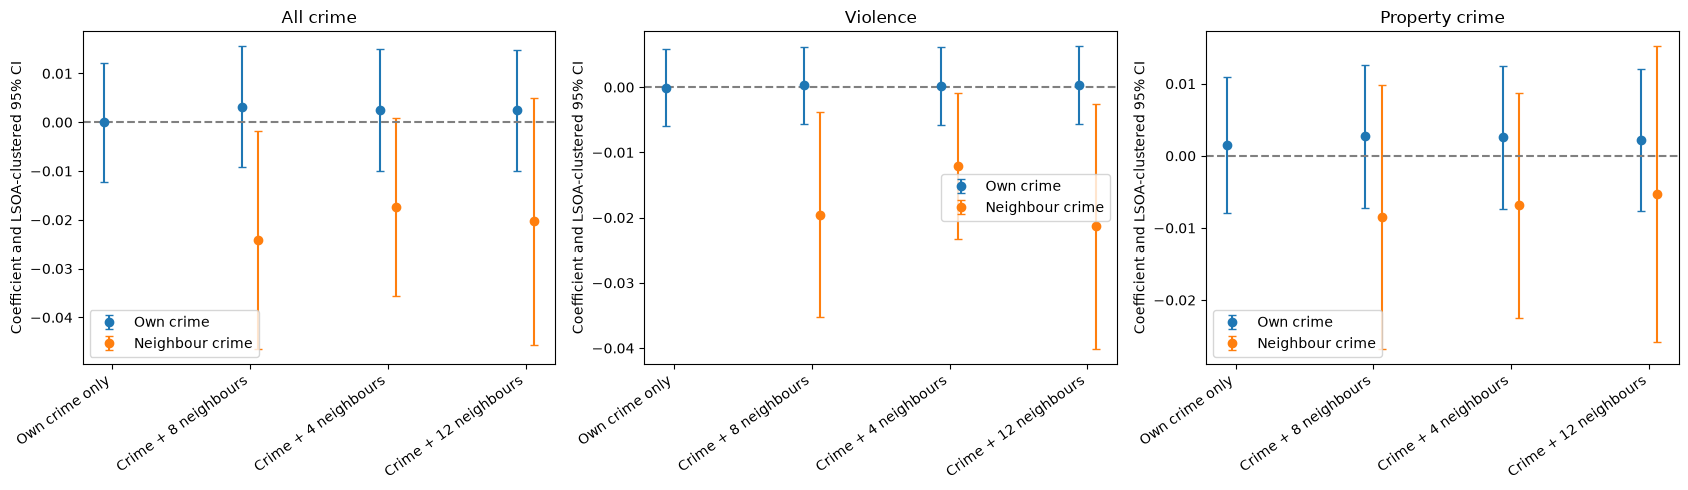

variable,beta,se,ci_low,ci_high
log1p_mps_all,-0.00002,0.00622,-0.01221,0.01217
detached_dum,0.63446,0.01470,0.60565,0.66327
semi_d_dum,0.36066,0.01325,0.33469,0.38664
terrace_dum,0.22823,0.01306,0.20262,0.25384
freehold,0.38859,0.01278,0.36355,0.41364
newbuild,0.18285,0.00966,0.16391,0.20179
tube_distnear_km,0.01092,0.01336,-0.01528,0.03711
bus_distnear_km,0.26402,0.02003,0.22476,0.30329
thamesriv_dist_km,-0.00748,0.01535,-0.03758,0.02262
dist_to_cbd,-0.01725,0.01753,-0.05161,0.01711


In [10]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
labels=[s[0] for s in settings]
for ax,category in zip(axes,MAIN):
    own=spatial_results.loc[spatial_results.crime.eq(category)].set_index('specification').reindex(labels)
    ax.errorbar(np.arange(len(settings))-.06,own.beta,yerr=np.vstack([own.beta-own.ci_low,own.ci_high-own.beta]),fmt='o',capsize=3,label='Own crime')
    neigh=spatial_coefficients.loc[spatial_coefficients.crime.eq(category)&spatial_coefficients.variable.str.startswith('W')].set_index('specification').reindex(labels)
    critical=stats.t.ppf(.975,slx.lsoacode.nunique()-1)
    ax.errorbar(np.arange(len(settings))+.06,neigh.beta,yerr=critical*neigh.se,fmt='o',capsize=3,label='Neighbour crime')
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(len(settings)),labels,rotation=35,ha='right')
    ax.set_title(CRIME_NAMES[category]);ax.set_ylabel('Coefficient and LSOA-clustered 95% CI');ax.legend()
fig.tight_layout();fig.savefig(OUT/'own_vs_neighbour_crime.png',dpi=170,bbox_inches='tight');plt.show()
from IPython.display import HTML
cards=[]
for (label,category),b in spatial_coefficients.groupby(['specification','crime'],sort=False):
    c=b[['variable','beta','se']].copy();c['ci_low']=c.beta-critical*c.se;c['ci_high']=c.beta+critical*c.se
    cards.append('<details style="margin:10px;padding:8px;border:1px solid #bbb"><summary>'+label+' / '+CRIME_NAMES[category]+'</summary>'+c.to_html(index=False,float_format=lambda x:f'{x:.5f}')+'</details>')
display(HTML(''.join(cards)))



## 3. Quarterly Moran diagnostics from transaction-level residuals

The own-crime and SLX price models above use identical transactions and LSOA/year-quarter fixed effects. Their sale residuals are averaged by LSOA-quarter only **after** fitting. For each quarter, Moran’s I uses the fixed neighbour graph restricted to LSOAs with sales; weights are renormalised and isolated LSOAs excluded. The quarter-specific number of LSOAs and sales is saved. Raw price and crime Moran values use the same quarterly spatial sample. Permutation p-values for fitted residuals are exploratory rather than exact post-estimation tests.

Only quarters with sales in all three months enter Moran diagnostics. The July-only 2015Q3 is excluded from these diagnostics but retained in the transaction-level regression sample; its coverage is saved separately.

The `_formatted` CSVs arrange the three neighbour definitions side by side. Moran values marked `*` have permutation p < 0.05; the adjacent p-value column gives the exact reported permutation p-value. There are 199 permutations, so the minimum attainable p-value is 0.0050. Residual p-values are exploratory because the regression residuals were estimated before the permutation calculation.

In [11]:
# Average the actual transaction-level M7-style residuals within each LSOA-quarter.
residual_names={}
quarter_source=slx[['lsoacode','yearquarter','lnprice']+['log1p_'+c for c in MAIN]].copy()
for (model,crime),residual in transaction_residuals.items():
    column='residual_'+model+'_'+crime
    assert len(residual)==len(quarter_source)
    quarter_source[column]=residual
    residual_names[(model,crime)]=column
quarterly=quarter_source.groupby(['yearquarter','lsoacode'],sort=True).mean(numeric_only=True)
quarterly['sales']=quarter_source.groupby(['yearquarter','lsoacode']).size()
quarterly=quarterly.reset_index()
# A July-only 2015Q3 would make the apparent change mostly a coverage change.
months_per_quarter=slx.groupby('yearquarter').sale_month.nunique()
partial=months_per_quarter.loc[months_per_quarter.lt(3)].rename('observed_months').reset_index()
partial['sales']=partial.yearquarter.map(slx.groupby('yearquarter').size())
partial.to_csv(OUT/'moran_excluded_partial_quarters.csv',index=False)
complete_quarters=months_per_quarter.index[months_per_quarter.eq(3)]
quarterly=quarterly.loc[quarterly.yearquarter.isin(complete_quarters)].copy()
quarterly['year']=quarterly.yearquarter.str[:4].astype(int)
quarterly.to_csv(OUT/'lsoa_quarter_panel.csv.gz',index=False,compression='gzip')

def moran(values,W,permutations=PERMUTATIONS,seed=SEED):
    z=np.asarray(values,float);z=z-z.mean()
    if z@z<1e-15:return np.nan,np.nan
    factor=len(z)/W.sum();observed=float(factor*(z@(W@z))/(z@z))
    rng=np.random.default_rng(seed)
    expected=-1/(len(z)-1)
    extreme=0
    for _ in range(permutations):
        shuffled=rng.permutation(z)
        simulated=float(factor*(shuffled@(W@shuffled))/(shuffled@shuffled))
        extreme+=abs(simulated-expected)>=abs(observed-expected)
    return observed,(extreme+1)/(permutations+1)

records=[];coverage=[]
code_index=pd.Index(codes)
for quarter_number,(quarter,group) in enumerate(quarterly.groupby('yearquarter',sort=True)):
    group=group.set_index('lsoacode').loc[code_index.intersection(group.lsoacode)]
    available=code_index.get_indexer(group.index)
    for k,W in weights.items():
        subset=W[available][:,available].tocsr()
        positions=np.arange(len(group))
        # Keep the fixed London graph; remove LSOAs with no observed neighbour this quarter.
        while True:
            nonisolated=np.asarray(subset.sum(axis=1)).ravel()>0
            if nonisolated.all():break
            subset=subset[nonisolated][:,nonisolated].tocsr()
            positions=positions[nonisolated]
        if len(positions)<30:raise ValueError(f'Too few linked LSOAs in {quarter}, k={k}')
        subset=sparse.diags(1/np.asarray(subset.sum(axis=1)).ravel())@subset
        observed=group.iloc[positions]
        coverage.append(dict(yearquarter=quarter,k=k,lsoas=len(observed),sales=int(observed.sales.sum()),excluded_isolated=len(group)-len(observed)))
        fields={'mean_log_price':'lnprice',**{crime:'log1p_'+crime for crime in MAIN},
                **{'residual_own_'+crime:residual_names[('own',crime)] for crime in MAIN},
                **{'residual_slx_'+crime:residual_names[('slx'+str(k),crime)] for crime in MAIN}}
        for variable,column in fields.items():
            I,p=moran(observed[column].to_numpy(),subset,seed=SEED+quarter_number*100+k)
            records.append(dict(k=k,yearquarter=quarter,year=int(quarter[:4]),variable=variable,
                                moran_I=I,permutation_p=p,permutations=PERMUTATIONS,
                                lsoas=len(observed),sales=int(observed.sales.sum())))
morans=pd.DataFrame(records)
coverage=pd.DataFrame(coverage)
table(coverage,'moran_quarterly_coverage')
assert morans.groupby(['k','yearquarter']).variable.nunique().eq(10).all()

# Copy-ready diagnostics; parentheses are own-crime model price-residual Moran's I.
wide=morans.pivot(index=['k','yearquarter'],columns='variable',values='moran_I').sort_index()
appendix=pd.DataFrame({
    'Neighbours':wide.index.get_level_values('k'),
    'Year-quarter':wide.index.get_level_values('yearquarter'),
    'LSOAs':coverage.set_index(['k','yearquarter']).loc[wide.index,'lsoas'].to_numpy(),
    'All crime (price residual)':[f'{a:.4f} ({b:.4f})' for a,b in zip(wide.mps_all,wide.residual_own_mps_all)],
    'Violent crime (price residual)':[f'{a:.4f} ({b:.4f})' for a,b in zip(wide.mps_violence,wide.residual_own_mps_violence)],
    'Property crime (price residual)':[f'{a:.4f} ({b:.4f})' for a,b in zip(wide.mps_property,wide.residual_own_mps_property)],
})
appendix.to_csv(OUT/'moran_diagnostics.csv',index=False)

# Keep the mean-price diagnostic separate from the crime/residual report table.
price_p=morans.loc[morans.variable.eq('mean_log_price')].set_index(['k','yearquarter']).loc[wide.index,'permutation_p']
price=pd.DataFrame({
    'Neighbours':wide.index.get_level_values('k'),
    'Year-quarter':wide.index.get_level_values('yearquarter'),
    'LSOAs':coverage.set_index(['k','yearquarter']).loc[wide.index,'lsoas'].to_numpy(),
    'Mean log house price':wide.mean_log_price.to_numpy(),
    'Permutation p-value':price_p.to_numpy(),
})
price.to_csv(OUT/'moran_diagnostics_price.csv',index=False)

# Report-ready tables: four decimal places and a star for p < 0.05.
# With 199 permutations, the smallest possible permutation p-value is 0.0050.
indexed=morans.set_index(['k','yearquarter','variable']).sort_index()
sample_sizes=coverage.set_index(['k','yearquarter']).lsoas
assert all(sample_sizes.loc[(8,q)]==sample_sizes.loc[(12,q)] for q in complete_quarters)
def formatted_i(row):
    return f"{row.moran_I:.4f}{'*' if row.permutation_p < 0.05 else ''}"
def formatted_p(row):
    return f"{row.permutation_p:.4f}"
def year_quarter_label(q):
    return q[:4]+' '+q[4:]

price_rows=[]
for q in sorted(complete_quarters):
    row={'Year-quarter':year_quarter_label(q)}
    for k in (4,8,12):
        result=indexed.loc[(k,q,'mean_log_price')]
        row[f'{k} neighbours · Moran I']=formatted_i(result)
        row[f'{k} neighbours · p-value']=formatted_p(result)
    row['LSOAs (4 NN)']=f'{sample_sizes.loc[(4,q)]:,}'
    row['LSOAs (8/12 NN)']=f'{sample_sizes.loc[(8,q)]:,}'
    price_rows.append(row)
price_formatted=pd.DataFrame(price_rows)
price_formatted.to_csv(OUT/'moran_diagnostics_price_formatted.csv',index=False)

crime_rows=[]
for q in sorted(complete_quarters):
    for crime in MAIN:
        row={'Year-quarter':year_quarter_label(q),'Crime type':CRIME_NAMES[crime]}
        for k in (4,8,12):
            crime_result=indexed.loc[(k,q,crime)]
            residual_result=indexed.loc[(k,q,'residual_own_'+crime)]
            row[f'{k} NN · crime Moran I']=formatted_i(crime_result)
            row[f'{k} NN · crime p-value']=formatted_p(crime_result)
            row[f'{k} NN · price residual Moran I']=formatted_i(residual_result)
            row[f'{k} NN · residual p-value']=formatted_p(residual_result)
        row['LSOAs (4 NN)']=f'{sample_sizes.loc[(4,q)]:,}'
        row['LSOAs (8/12 NN)']=f'{sample_sizes.loc[(8,q)]:,}'
        crime_rows.append(row)
crime_formatted=pd.DataFrame(crime_rows)
crime_formatted.to_csv(OUT/'moran_diagnostics_crime_formatted.csv',index=False)

residual_check=morans.loc[morans.variable.str.startswith('residual_own_')]
print('Quarterly own-crime residual Moran I range:',
      f'{residual_check.moran_I.min():.4f} to {residual_check.moran_I.max():.4f}')
print('Quarterly own-crime residuals significant at 5%:',
      int(residual_check.permutation_p.lt(.05).sum()),'of',len(residual_check))
display(price_formatted.head(3),crime_formatted.head(3))

# Compare spatial residual clustering before and after adding neighbouring crime.
comparison=morans.loc[morans.variable.str.startswith('residual_')].copy()
comparison['crime']=comparison.variable.str.extract(r'(mps_(?:all|violence|property))$')[0]
comparison['model']=np.where(comparison.variable.str.startswith('residual_own_'),'Own crime only','Own + matching neighbours')
comparison.to_csv(OUT/'moran_residual_comparison.csv',index=False)
display(appendix.head(12))

,yearquarter,k,lsoas,sales,excluded_isolated
0,2012Q1,4,4225,19766,1
1,2012Q1,8,4226,19767,0
2,2012Q1,12,4226,19767,0
3,2012Q2,4,4128,19088,0
4,2012Q2,8,4128,19088,0
5,2012Q2,12,4128,19088,0
6,2012Q3,4,4226,22394,1
7,2012Q3,8,4227,22395,0
8,2012Q3,12,4227,22395,0
9,2012Q4,4,4199,21199,1


Showing 20 of 42 rows; the complete table is saved as moran_quarterly_coverage.csv.
Quarterly own-crime residual Moran I range: -0.0164 to 0.0879
Quarterly own-crime residuals significant at 5%: 78 of 126


,Year-quarter,4 neighbours · Moran I,4 neighbours · p-value,8 neighbours · Moran I,8 neighbours · p-value,12 neighbours · Moran I,12 neighbours · p-value,LSOAs (4 NN),LSOAs (8/12 NN)
0,2012 Q1,0.6268*,0.0050,0.6090*,0.0050,0.5942*,0.0050,"4,225","4,226"
1,2012 Q2,0.6243*,0.0050,0.6107*,0.0050,0.5989*,0.0050,"4,128","4,128"
2,2012 Q3,0.6495*,0.0050,0.6316*,0.0050,0.6190*,0.0050,"4,226","4,227"


,Year-quarter,Crime type,4 NN · crime Moran I,4 NN · crime p-value,4 NN · price residual Moran I,4 NN · residual p-value,...,12 NN · crime Moran I,12 NN · crime p-value,12 NN · price residual Moran I,12 NN · residual p-value,LSOAs (4 NN),LSOAs (8/12 NN)
0,2012 Q1,All crime,0.4368*,0.0050,0.0835*,0.0050,...,0.3830*,0.0050,0.0879*,0.0050,"4,225","4,226"
1,2012 Q1,Violence,0.4310*,0.0050,0.0835*,0.0050,...,0.3761*,0.0050,0.0879*,0.0050,"4,225","4,226"
2,2012 Q1,Property crime,0.3872*,0.0050,0.0834*,0.0050,...,0.3308*,0.0050,0.0879*,0.0050,"4,225","4,226"


,Neighbours,Year-quarter,LSOAs,All crime (price residual),Violent crime (price residual),Property crime (price residual)
0,4,2012Q1,4225,0.4368 (0.0835),0.4310 (0.0835),0.3872 (0.0834)
1,4,2012Q2,4128,0.4418 (0.0088),0.4380 (0.0088),0.3909 (0.0088)
2,4,2012Q3,4226,0.4311 (0.0183),0.4301 (0.0183),0.3805 (0.0184)
3,4,2012Q4,4199,0.4246 (0.0252),0.4304 (0.0252),0.3743 (0.0252)
4,4,2013Q1,4184,0.4230 (0.0135),0.4352 (0.0135),0.3733 (0.0135)
5,4,2013Q2,4225,0.4217 (0.0171),0.4282 (0.0171),0.3749 (0.0171)
6,4,2013Q3,4338,0.4137 (0.0028),0.4273 (0.0028),0.3632 (0.0028)
7,4,2013Q4,4324,0.4184 (-0.0164),0.4448 (-0.0164),0.3673 (-0.0164)
8,4,2014Q1,4305,0.4195 (-0.0065),0.4514 (-0.0065),0.3698 (-0.0065)
9,4,2014Q2,4325,0.4159 (0.0457),0.4538 (0.0457),0.3613 (0.0458)


### Quarterly spatial patterns and own-versus-neighbour residuals

The first figure shows three crime types and price residuals from the own-crime model across 4, 8, and 12 neighbours. Mean log house-price Moran values are exported separately in `moran_diagnostics_price.csv`. The second compares residual clustering for the own-crime benchmark and the 8-neighbour SLX model on the same transactions.

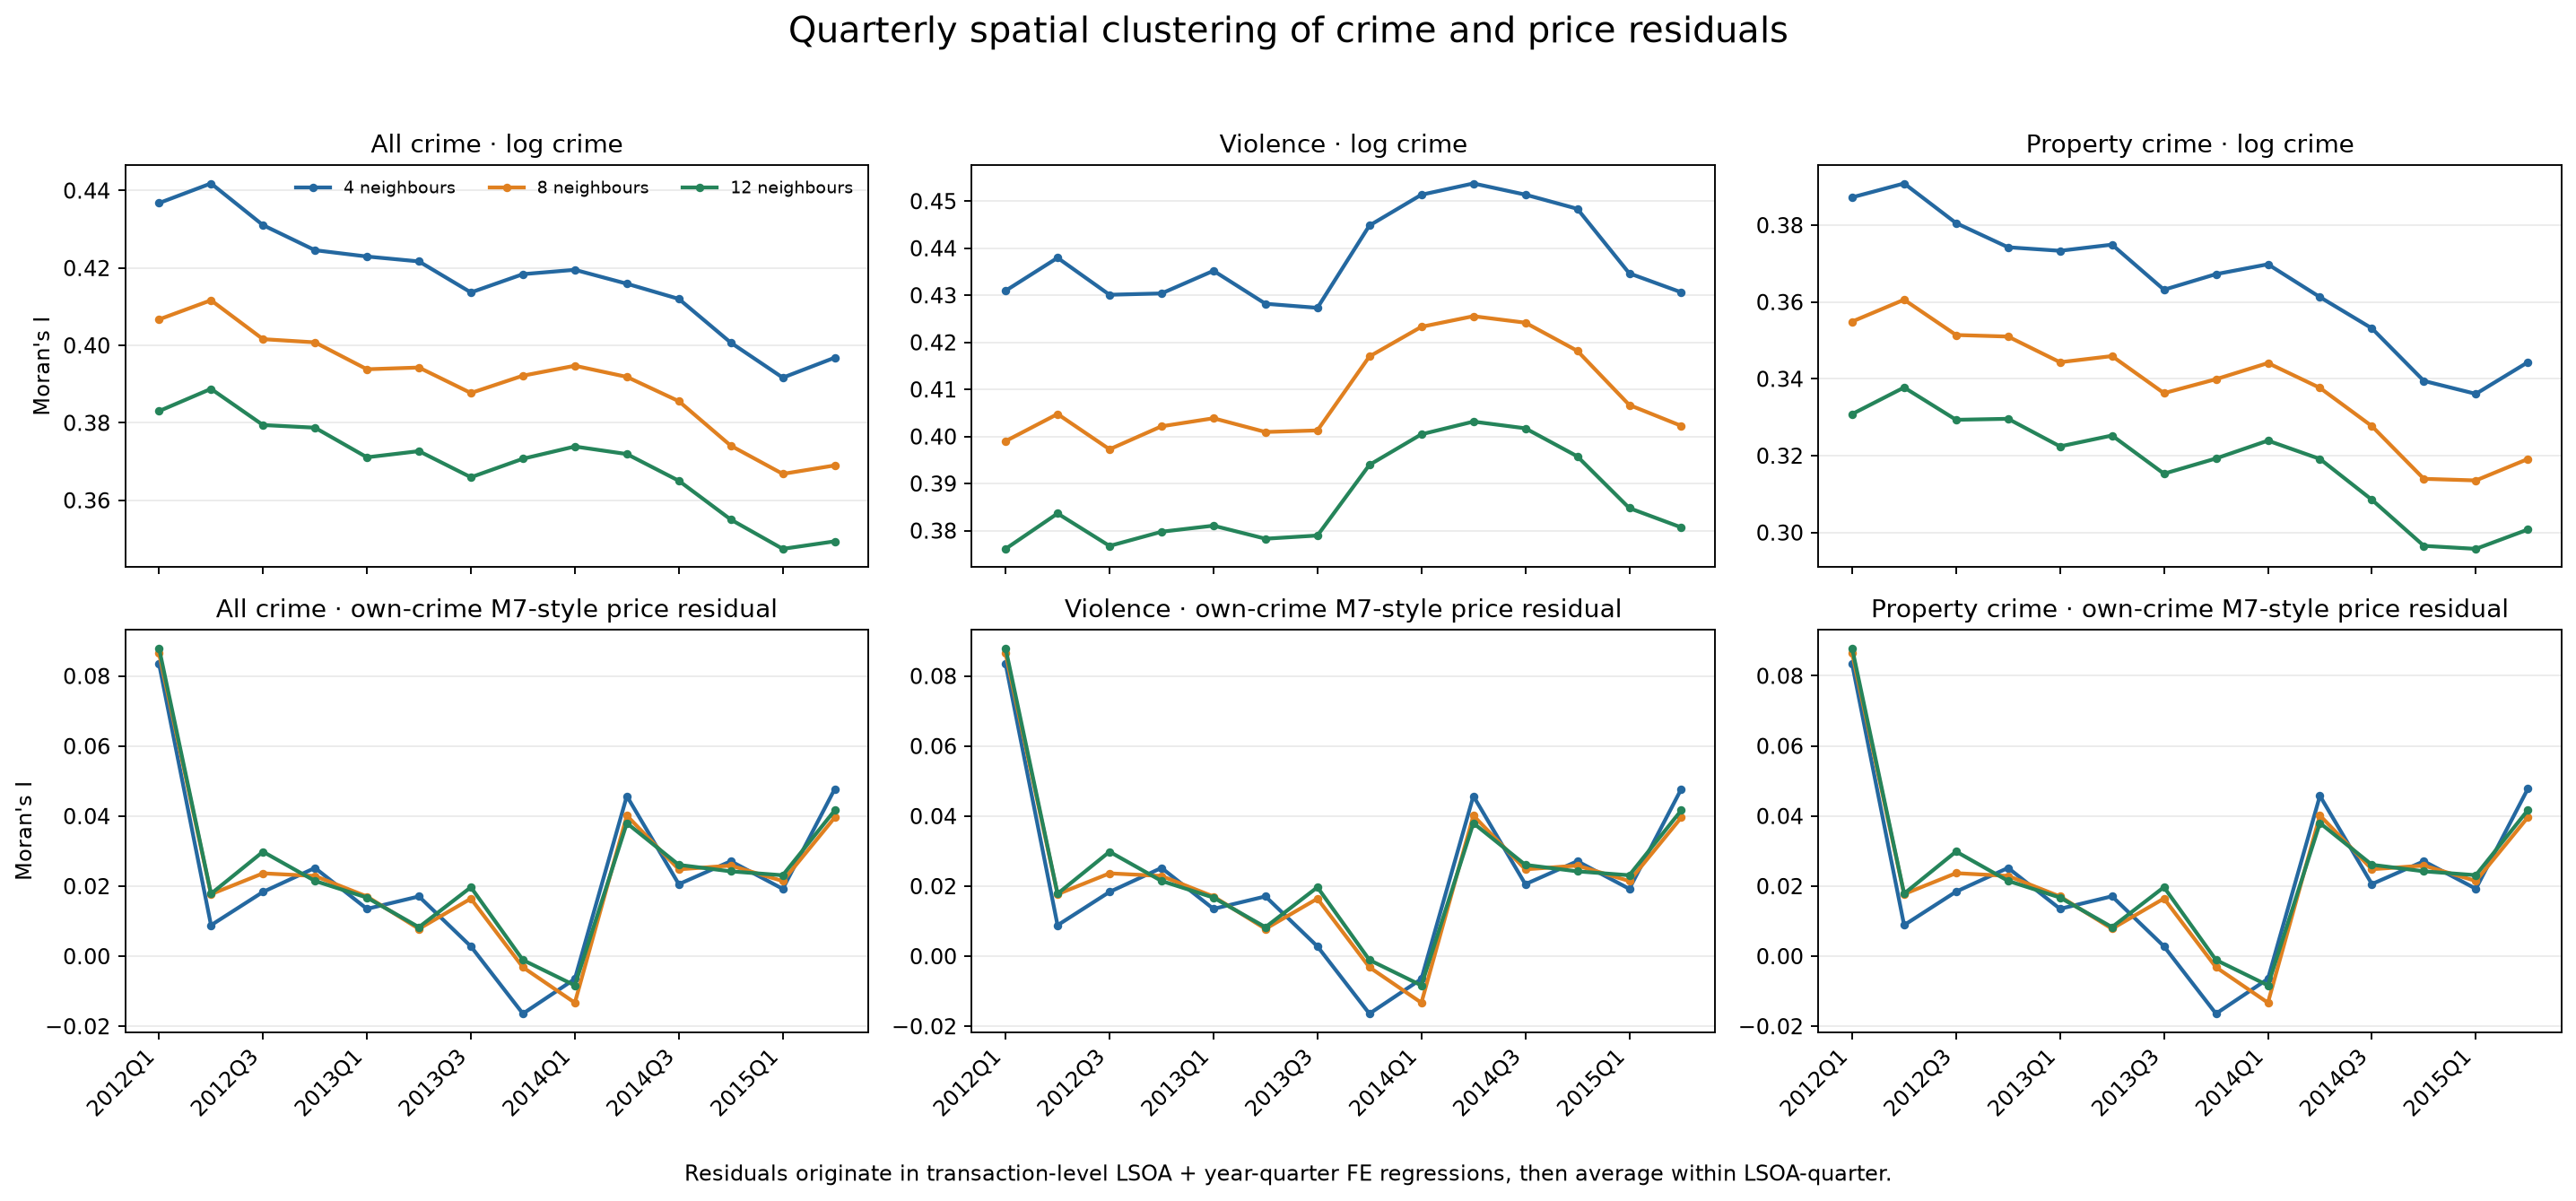

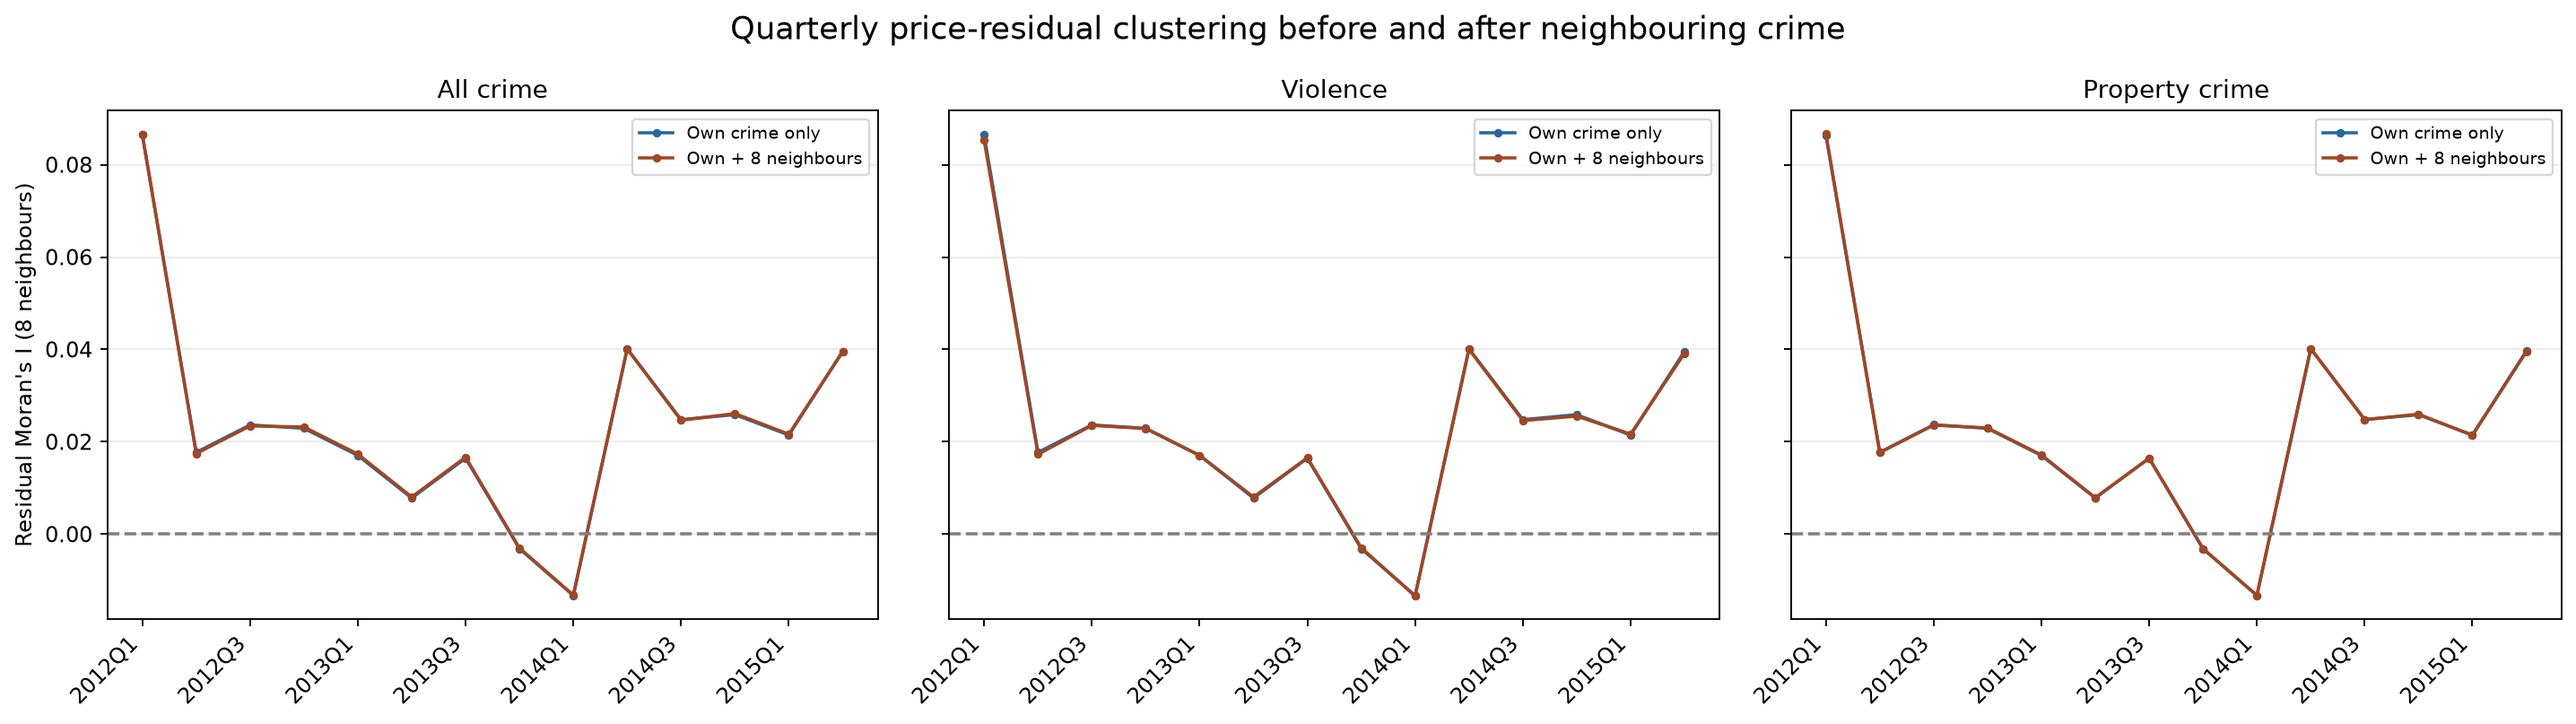

In [12]:
from IPython.display import Image,display
colours={4:'#2468a0',8:'#e08020',12:'#25845a'}
quarters=sorted(morans.yearquarter.unique())
x_positions=np.arange(len(quarters))
fig,axes=plt.subplots(2,3,figsize=(17,7.8),sharex='col')
crime_axes=axes[0]
residual_axes=axes[1]
def draw(ax,variable,title):
    for k,colour in colours.items():
        b=morans.loc[morans.k.eq(k)&morans.variable.eq(variable)].set_index('yearquarter').reindex(quarters)
        ax.plot(x_positions,b.moran_I,marker='o',markersize=3,linewidth=1.8,color=colour,label=f'{k} neighbours')
    ax.set_title(title)
    ax.grid(axis='y',alpha=.25)
    ax.set_xticks(x_positions[::2],[q for q in quarters[::2]],rotation=45,ha='right')
for j,crime in enumerate(MAIN):
    draw(crime_axes[j],crime,CRIME_NAMES[crime]+' · log crime')
    draw(residual_axes[j],'residual_own_'+crime,CRIME_NAMES[crime]+' · own-crime M7-style price residual')
crime_axes[0].set_ylabel("Moran's I")
crime_axes[0].legend(ncol=3,frameon=False,loc="upper right",fontsize=8)
residual_axes[0].set_ylabel("Moran's I")
fig.suptitle('Quarterly spatial clustering of crime and price residuals',fontsize=17,y=.99)
fig.text(.5,.01,'Residuals originate in transaction-level LSOA + year-quarter FE regressions, then average within LSOA-quarter.',ha='center',fontsize=10)
fig.tight_layout(rect=[0,.04,1,.96])
figure_path=OUT/'moran_full_by_quarter_and_neighbours.png'
fig.savefig(figure_path,dpi=170,bbox_inches='tight');plt.close(fig)
display(Image(filename=str(figure_path)))

fig,axes=plt.subplots(1,3,figsize=(17,4.8),sharey=True)
for ax,crime in zip(axes,MAIN):
    for model,colour,label in [('Own crime only','#2468a0','Own crime only'),('Own + matching neighbours','#a04724','Own + 8 neighbours')]:
        b=comparison.loc[comparison.k.eq(8)&comparison.crime.eq(crime)&comparison.model.eq(model)].set_index('yearquarter').reindex(quarters)
        ax.plot(x_positions,b.moran_I,marker='o',markersize=3,color=colour,label=label)
    ax.set_title(CRIME_NAMES[crime]);ax.set_xticks(x_positions[::2],quarters[::2],rotation=45,ha='right')
    ax.axhline(0,color='grey',linestyle='--');ax.grid(axis='y',alpha=.25);ax.legend(fontsize=8)
axes[0].set_ylabel("Residual Moran's I (8 neighbours)")
fig.suptitle('Quarterly price-residual clustering before and after neighbouring crime',fontsize=15)
fig.tight_layout()
comparison_path=OUT/'moran_residual_own_vs_slx8.png'
fig.savefig(comparison_path,dpi=170,bbox_inches='tight');plt.close(fig)
display(Image(filename=str(comparison_path)))

## 4. Interpretation and limitations

The quarterly Moran diagnostics now describe raw prices, crime, and price residuals on the same spatial transaction sample used by the SLX regressions. The residuals come from transaction-level models with LSOA and year-quarter fixed effects, then are averaged by LSOA-quarter for spatial analysis. The balanced annual sale-coverage rule only defines the initial LSOA graph; it is not the residual regression.

Spatial clustering does not establish that crime causes prices or that neighbouring crime has a causal spillover. Quarter-specific missing sales and noisy means affect Moran diagnostics. Reusing estimated residuals in a permutation test makes the reported p-values exploratory. LSOA-clustered errors in the SLX regressions do not fully address cross-LSOA dependence. The representative locations are averages of sale points, not official centroids, and nearest areas may lie across physical barriers.